# 16 · Cost-sensitive decision analysis

## Purpose

Compare random, probability-only, fixed-threshold, cost-sensitive, calibration-aware, and uncertainty-aware review under explicit low, medium, and high cost assumptions.

## Method

Evaluate only on the decision-study labeled holdout. Compute precision@K, recall@K, realized false positives/negatives, expected-decision-cost formula, and reviewed-case counts at 5%, 10%, 20%, and 30% capacities.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Cost values are illustrative scenario inputs, not actual business measurements. Results do not demonstrate causal return prevention or profit.

## References

Decision equations and interpretation boundaries: docs/references.md


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '16 · Cost-sensitive decision analysis')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 16 · Cost-sensitive decision analysis


,scenario,strategy,capacity_percent,capacity_rows,review_count,false_positive_cost_assumption,false_negative_cost_assumption,review_cost_assumption,expected_decision_cost,false_positives,false_negatives,return_cases_identified,precision_at_k,recall_at_k,count_type,roc_auc,pr_auc,brier_score,log_loss
0,low,random,5.0,1600,1600,0.5,2.0,0.1,29466.5,853,14440,747,0.466875,0.049187,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976
1,low,probability_only,5.0,1600,1600,0.5,2.0,0.1,28666.5,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976
2,low,fixed_threshold,5.0,1600,1600,0.5,2.0,0.1,28666.5,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976
3,low,cost_sensitive,5.0,1600,1600,0.5,2.0,0.1,28666.5,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976
4,low,calibration_aware_cost_sensitive,5.0,1600,1600,0.5,2.0,0.1,28666.5,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,high,probability_only,30.0,9600,9600,2.0,10.0,0.5,110794.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976
68,high,fixed_threshold,30.0,9600,9600,2.0,10.0,0.5,110794.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976
69,high,cost_sensitive,30.0,9600,9600,2.0,10.0,0.5,110794.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976
70,high,calibration_aware_cost_sensitive,30.0,9600,9600,2.0,10.0,0.5,110794.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313


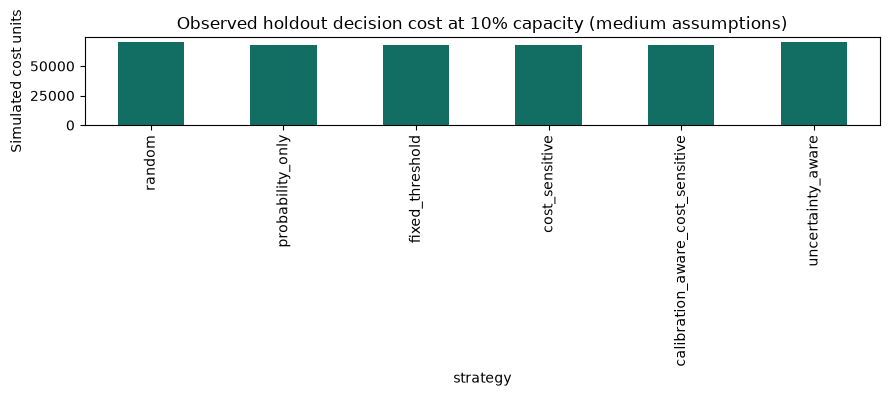

In [2]:
from returnwise.decision import evaluate_review_strategies
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt
import pandas as pd

state = load_state()
predictions = state['decision_predictions']
calibrator = state['decision_calibrator_name']
probability = predictions[f'probability_{calibrator}'].to_numpy()
raw = predictions['probability_uncalibrated'].to_numpy()
y_true = predictions['y_true'].to_numpy()
scenarios = {
    'low': {'false_positive': 0.5, 'false_negative': 2.0, 'review': 0.1},
    'medium': {'false_positive': 1.0, 'false_negative': 5.0, 'review': 0.25},
    'high': {'false_positive': 2.0, 'false_negative': 10.0, 'review': 0.5},
}
parts = []
for scenario, costs in scenarios.items():
    result = evaluate_review_strategies(raw, y_true=y_true, calibrated_probabilities=probability, costs=costs)
    result.insert(0, 'scenario', scenario)
    parts.append(result)
decision_results = pd.concat(parts, ignore_index=True)
display(decision_results)
plot = decision_results[(decision_results['scenario'] == 'medium') & (decision_results['capacity_percent'] == 10)]
ax = plot.plot.bar(x='strategy', y='expected_decision_cost', figsize=(9, 4), legend=False, color='#126E63', title='Observed holdout decision cost at 10% capacity (medium assumptions)')
ax.set_ylabel('Simulated cost units')
plt.tight_layout()
plt.show()
state.update({'decision_results': decision_results, 'cost_scenarios': scenarios})
from returnwise.experiments import log_experiment
log_experiment('Cost-sensitive decision analysis', None,
               {'results': decision_results.to_dict(orient='records')}, {'scenarios': scenarios})
save_state(state)
